In [1]:
# 환자별 성능 계산
import json
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/home/stu03/workspace/model")

RESULT_DIR = (
    ROOT
    / "runs/nnunet/Dataset001_ICHBinary"
    / "nnUNetTrainerICHBaseline__ICHPlansResEncMAttentionV1__3d_fullres"
    / "fold_0/validation"
)

SUMMARY_FILE = RESULT_DIR / "summary.json"

summary = json.loads(SUMMARY_FILE.read_text(encoding="utf-8"))

rows = []

for item in summary["metric_per_case"]:
    metric = item["metrics"]["1"]

    gt_voxels = int(metric["n_ref"])
    pred_voxels = int(metric["n_pred"])
    tp = int(metric["TP"])
    fp = int(metric["FP"])
    fn = int(metric["FN"])

    reference_file = Path(item["reference_file"])
    prediction_file = Path(item["prediction_file"])

    # voxel 크기를 이용해 실제 출혈 부피(mL) 계산
    reference_image = nib.load(reference_file)
    voxel_volume_mm3 = float(np.prod(reference_image.header.get_zooms()[:3]))

    gt_volume_ml = gt_voxels * voxel_volume_mm3 / 1000
    pred_volume_ml = pred_voxels * voxel_volume_mm3 / 1000

    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan

    rows.append({
        "case": reference_file.name.replace(".nii.gz", ""),
        "reference_file": str(reference_file),
        "prediction_file": str(prediction_file),
        "gt_volume_ml": gt_volume_ml,
        "pred_volume_ml": pred_volume_ml,
        "dice": metric["Dice"],
        "recall": recall,
        "precision": precision,
        "tp": tp,
        "fp": fp,
        "fn": fn,
    })

df = pd.DataFrame(rows)

positive_df = df[df["gt_volume_ml"] > 0].copy()

print("전체 검증 환자:", len(df))
print("출혈 양성 환자:", len(positive_df))

display(
    positive_df[
        [
            "case",
            "gt_volume_ml",
            "pred_volume_ml",
            "dice",
            "recall",
            "precision",
        ]
    ].sort_values("dice")
)

전체 검증 환자: 40
출혈 양성 환자: 35


,case,gt_volume_ml,pred_volume_ml,dice,recall,precision
2,BHSD_ID_0b10cbee_ID_f91d6a7cd2,2.676365,0.258038,0.000000,0.000000,0.000000
7,BHSD_ID_47aa2b3a_ID_95a9953aba,0.178717,2.590614,0.000000,0.000000,0.000000
34,PHYS_58,0.252899,0.186728,0.000000,0.000000,0.000000
38,PHYS_82,1.694899,0.000000,0.000000,0.000000,NaN
37,PHYS_78,5.720863,3.677758,0.001988,0.001633,0.002540
21,BHSD_ID_a72de500_ID_87b2b4fc60,0.369558,3.851840,0.092832,0.530201,0.050869
12,BHSD_ID_6c85adda_ID_86bc0ab248,1.322407,4.634467,0.275568,0.620658,0.177100
18,BHSD_ID_9dce269b_ID_4191982e02,60.555762,27.214478,0.309730,0.224463,0.499460
8,BHSD_ID_55742eb7_ID_7d5ad548ca,6.922483,2.120733,0.310572,0.202859,0.662170
33,PHYS_51,32.834883,11.417949,0.400553,0.269920,0.776216


In [2]:
# 병변 크기별 성능
positive_df["size_group"] = pd.cut(
    positive_df["gt_volume_ml"],
    bins=[0, 1, 5, 20, np.inf],
    labels=["<1 mL", "1–5 mL", "5–20 mL", "≥20 mL"],
    include_lowest=True,
)

size_results = (
    positive_df
    .groupby("size_group", observed=False)
    .agg(
        cases=("case", "count"),
        mean_volume_ml=("gt_volume_ml", "mean"),
        mean_dice=("dice", "mean"),
        median_dice=("dice", "median"),
        mean_recall=("recall", "mean"),
        mean_precision=("precision", "mean"),
    )
    .reset_index()
)

display(size_results.round(3))

,size_group,cases,mean_volume_ml,mean_dice,median_dice,mean_recall,mean_precision
0,<1 mL,3,0.267,0.031,0.000,0.177,0.017
1,1–5 mL,8,3.255,0.411,0.415,0.439,0.502
2,5–20 mL,8,12.203,0.501,0.477,0.477,0.599
3,≥20 mL,16,64.524,0.744,0.847,0.757,0.767


/home/stu03/workspace/model/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 52636 (\N{HANGUL SYLLABLE CUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/stu03/workspace/model/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54792 (\N{HANGUL SYLLABLE HYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/stu03/workspace/model/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 53356 (\N{HANGUL SYLLABLE KEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/stu03/workspace/model/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/stu03/workspace/model/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Gly

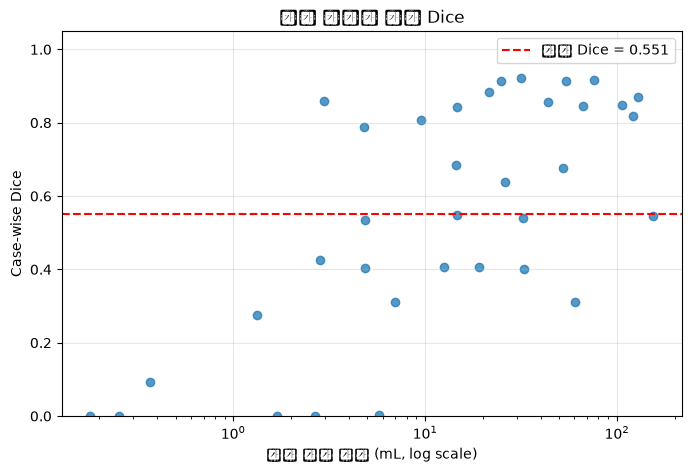

출혈 크기와 Dice의 Spearman 상관계수: 0.626


In [3]:
# 출혈 크기와 Dice 관계
plt.figure(figsize=(8, 5))

plt.scatter(
    positive_df["gt_volume_ml"],
    positive_df["dice"],
    alpha=0.75,
)

plt.xscale("log")
plt.axhline(
    positive_df["dice"].mean(),
    color="red",
    linestyle="--",
    label=f"평균 Dice = {positive_df['dice'].mean():.3f}",
)

plt.xlabel("정답 출혈 부피 (mL, log scale)")
plt.ylabel("Case-wise Dice")
plt.title("출혈 크기에 따른 Dice")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

correlation = positive_df[
    ["gt_volume_ml", "dice"]
].corr(method="spearman").iloc[0, 1]

print(f"출혈 크기와 Dice의 Spearman 상관계수: {correlation:.3f}")

In [4]:
# 성능이 가장 낮은 환자 확인
worst_cases = positive_df.nsmallest(10, "dice")

display(
    worst_cases[
        [
            "case",
            "gt_volume_ml",
            "dice",
            "recall",
            "precision",
            "fp",
            "fn",
        ]
    ].round(3)
)

,case,gt_volume_ml,dice,recall,precision,fp,fn
2,BHSD_ID_0b10cbee_ID_f91d6a7cd2,2.676,0.000,0.000,0.000,207,2147
7,BHSD_ID_47aa2b3a_ID_95a9953aba,0.179,0.000,0.000,0.000,1667,115
34,PHYS_58,0.253,0.000,0.000,0.000,206,279
38,PHYS_82,1.695,0.000,0.000,NaN,0,2015
37,PHYS_78,5.721,0.002,0.002,0.003,4320,6726
21,BHSD_ID_a72de500_ID_87b2b4fc60,0.370,0.093,0.530,0.051,2948,140
12,BHSD_ID_6c85adda_ID_86bc0ab248,1.322,0.276,0.621,0.177,3155,415
18,BHSD_ID_9dce269b_ID_4191982e02,60.556,0.310,0.224,0.499,11130,38372
8,BHSD_ID_55742eb7_ID_7d5ad548ca,6.922,0.311,0.203,0.662,601,4629
33,PHYS_51,32.835,0.401,0.270,0.776,3009,28230


Case: BHSD_ID_0b10cbee_ID_f91d6a7cd2
CT shape: (512, 512, 32)
GT shape: (512, 512, 32)
Prediction shape: (512, 512, 32)


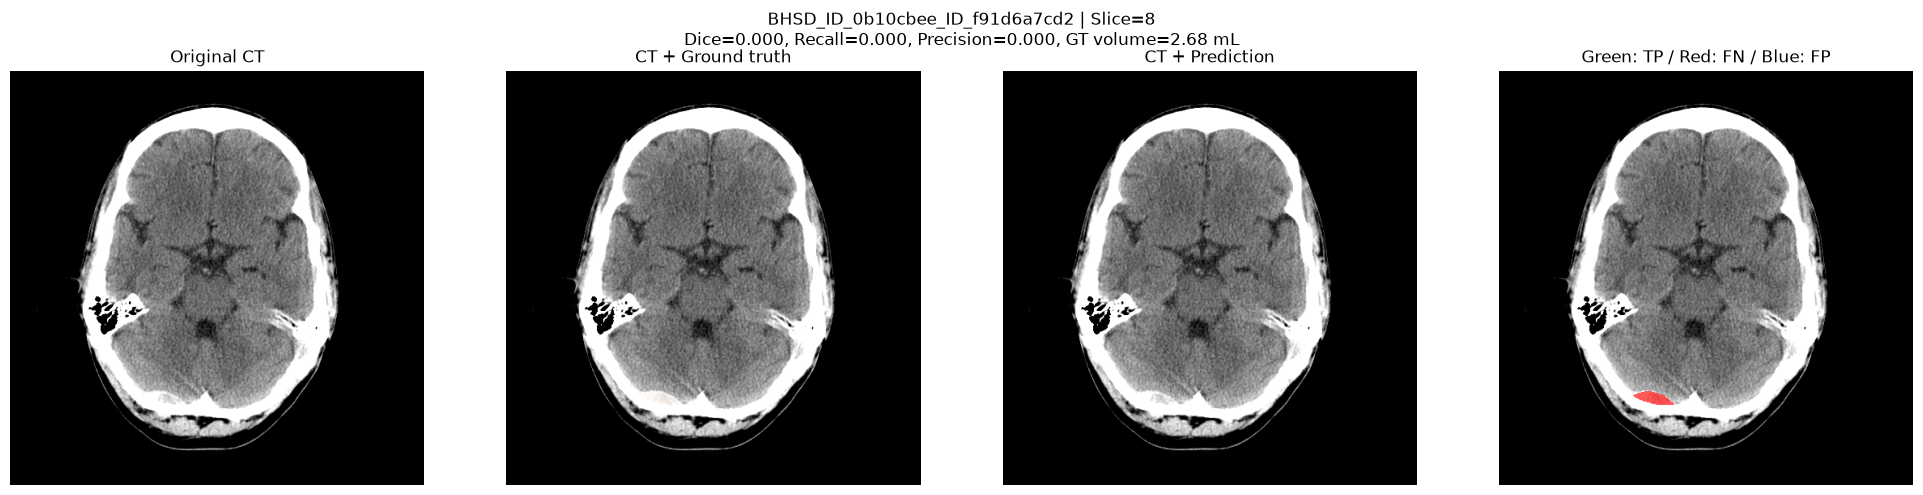

Case: BHSD_ID_47aa2b3a_ID_95a9953aba
CT shape: (512, 512, 24)
GT shape: (512, 512, 24)
Prediction shape: (512, 512, 24)


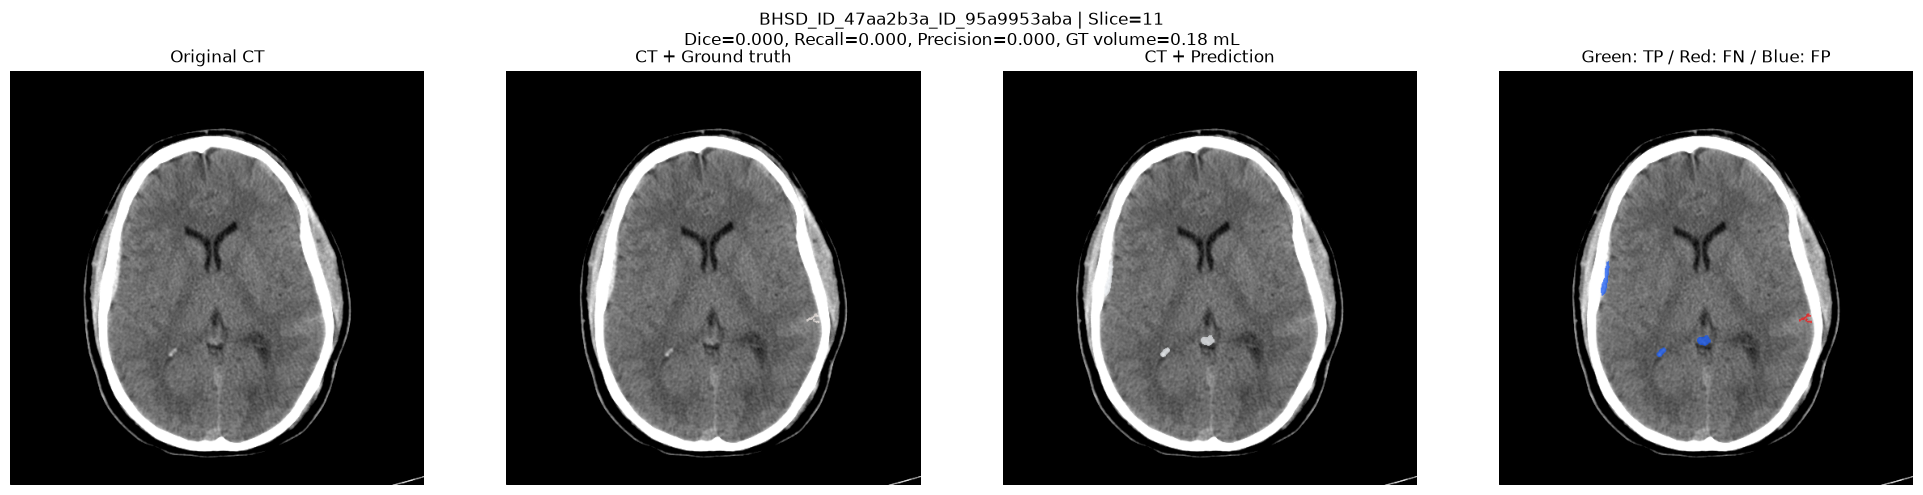

Case: PHYS_58
CT shape: (512, 512, 38)
GT shape: (512, 512, 38)
Prediction shape: (512, 512, 38)


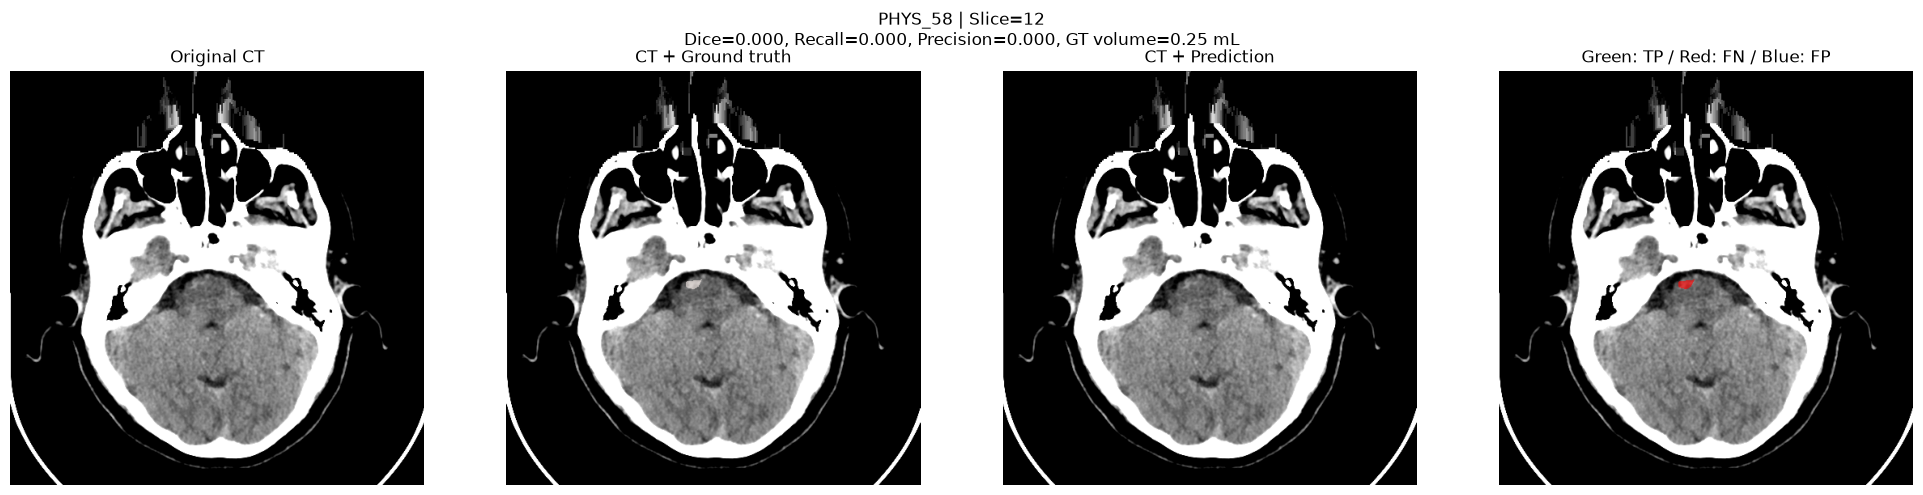

Case: PHYS_82
CT shape: (512, 512, 34)
GT shape: (512, 512, 34)
Prediction shape: (512, 512, 34)


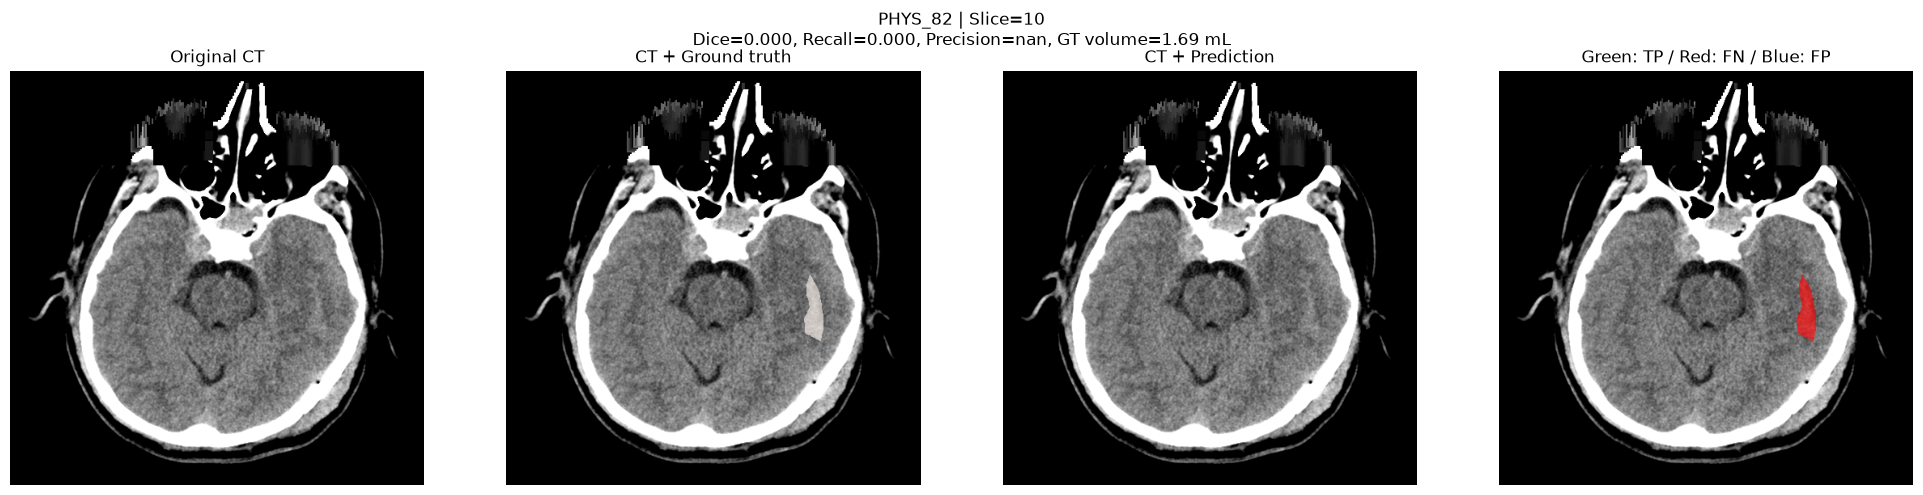

Case: PHYS_78
CT shape: (512, 512, 36)
GT shape: (512, 512, 36)
Prediction shape: (512, 512, 36)


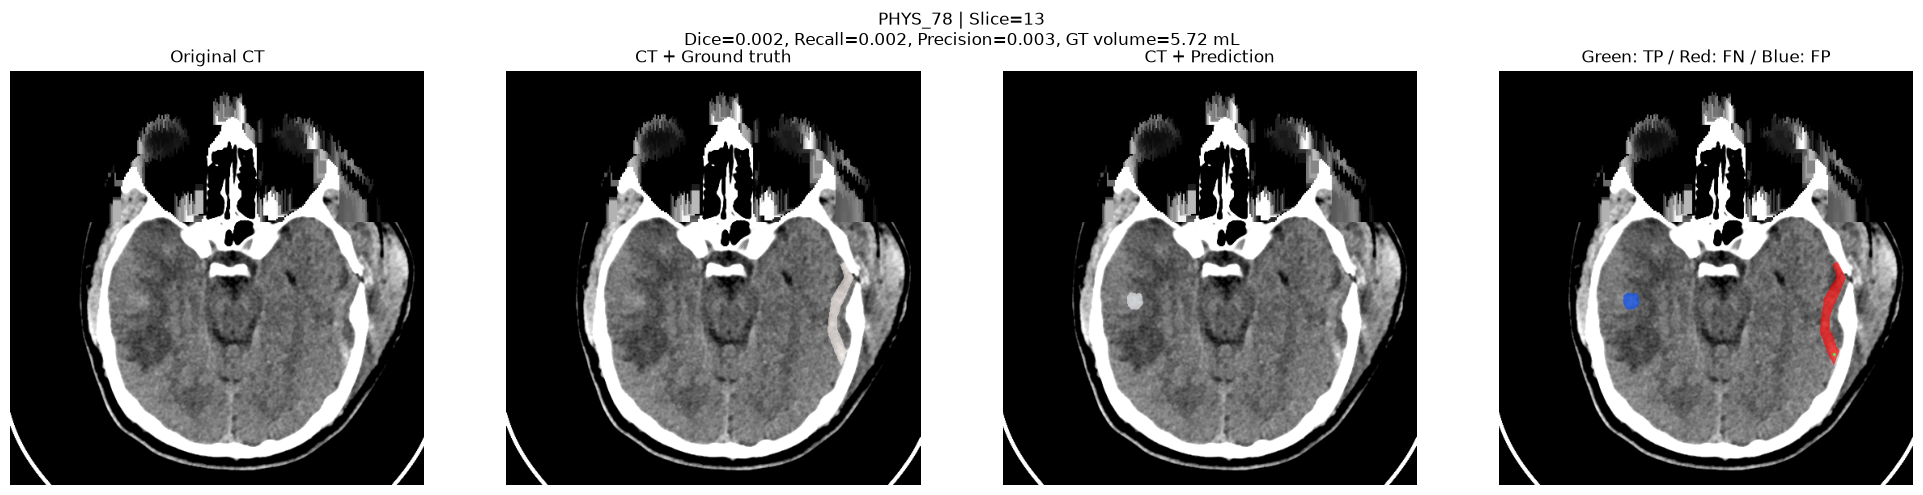

In [6]:
RAW_IMAGE_DIR = (
    ROOT.parent
    / "datasets/hemorrhage/v1/model_ready/nnunet"
    / "nnUNet_raw/Dataset001_ICHBinary/imagesTr"
)


def normalize_ct(ct_slice, window_center=40, window_width=80):
    """
    기본 brain window:
    center=40 HU, width=80 HU
    """
    lower = window_center - window_width / 2
    upper = window_center + window_width / 2

    ct_slice = np.clip(ct_slice, lower, upper)
    ct_slice = (ct_slice - lower) / (upper - lower)

    return ct_slice


def find_raw_image(case_name):
    candidates = [
        RAW_IMAGE_DIR / f"{case_name}_0000.nii.gz",
        RAW_IMAGE_DIR / f"{case_name}.nii.gz",
    ]

    for path in candidates:
        if path.exists():
            return path

    raise FileNotFoundError(
        f"원본 CT를 찾을 수 없습니다: {case_name}"
    )


def show_case_with_ct(row):
    case_name = row["case"]

    raw_path = find_raw_image(case_name)

    ct_image = nib.load(raw_path)
    gt_image = nib.load(row["reference_file"])
    pred_image = nib.load(row["prediction_file"])

    ct = np.asarray(ct_image.dataobj, dtype=np.float32)
    gt = np.asarray(gt_image.dataobj) > 0
    pred = np.asarray(pred_image.dataobj) > 0

    print("Case:", case_name)
    print("CT shape:", ct.shape)
    print("GT shape:", gt.shape)
    print("Prediction shape:", pred.shape)

    if ct.shape != gt.shape or gt.shape != pred.shape:
        raise ValueError(
            "CT, GT, Prediction 크기가 서로 다릅니다. "
            "원본 영상과 예측 결과의 공간 정렬을 확인해야 합니다."
        )

    # 정답 병변이 가장 많이 포함된 axial slice
    if gt.any():
        slice_index = int(
            np.argmax(gt.sum(axis=(0, 1)))
        )
    elif pred.any():
        slice_index = int(
            np.argmax(pred.sum(axis=(0, 1)))
        )
    else:
        slice_index = ct.shape[2] // 2

    ct_slice = normalize_ct(ct[:, :, slice_index])
    gt_slice = gt[:, :, slice_index]
    pred_slice = pred[:, :, slice_index]

    tp = gt_slice & pred_slice
    fn = gt_slice & ~pred_slice
    fp = ~gt_slice & pred_slice

    # CT를 RGB 영상으로 변환
    overlay = np.stack(
        [ct_slice, ct_slice, ct_slice],
        axis=-1,
    )

    # 색상
    green = np.array([0.0, 1.0, 0.0])  # TP
    red = np.array([1.0, 0.0, 0.0])    # FN
    blue = np.array([0.0, 0.3, 1.0])   # FP

    alpha = 0.65

    overlay[tp] = (
        (1 - alpha) * overlay[tp]
        + alpha * green
    )
    overlay[fn] = (
        (1 - alpha) * overlay[fn]
        + alpha * red
    )
    overlay[fp] = (
        (1 - alpha) * overlay[fp]
        + alpha * blue
    )

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20, 5),
    )

    axes[0].imshow(
        ct_slice.T,
        cmap="gray",
        origin="lower",
    )
    axes[0].set_title("Original CT")

    axes[1].imshow(
        ct_slice.T,
        cmap="gray",
        origin="lower",
    )
    axes[1].imshow(
        np.ma.masked_where(~gt_slice.T, gt_slice.T),
        cmap="Reds",
        alpha=0.6,
        origin="lower",
    )
    axes[1].set_title("CT + Ground truth")

    axes[2].imshow(
        ct_slice.T,
        cmap="gray",
        origin="lower",
    )
    axes[2].imshow(
        np.ma.masked_where(~pred_slice.T, pred_slice.T),
        cmap="Blues",
        alpha=0.6,
        origin="lower",
    )
    axes[2].set_title("CT + Prediction")

    axes[3].imshow(
        overlay.transpose(1, 0, 2),
        origin="lower",
    )
    axes[3].set_title(
        "Green: TP / Red: FN / Blue: FP"
    )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"{case_name} | Slice={slice_index}\n"
        f"Dice={row['dice']:.3f}, "
        f"Recall={row['recall']:.3f}, "
        f"Precision={row['precision']:.3f}, "
        f"GT volume={row['gt_volume_ml']:.2f} mL"
    )

    plt.tight_layout()
    plt.show()


for _, row in worst_cases.head(5).iterrows():
    show_case_with_ct(row)

In [7]:
row = worst_cases.iloc[0]

ct_image = nib.load(find_raw_image(row["case"]))
gt_image = nib.load(row["reference_file"])
pred_image = nib.load(row["prediction_file"])

print(
    "CT와 GT affine 동일:",
    np.allclose(ct_image.affine, gt_image.affine),
)
print(
    "CT와 예측 affine 동일:",
    np.allclose(ct_image.affine, pred_image.affine),
)

CT와 GT affine 동일: True
CT와 예측 affine 동일: True


In [8]:
for minimum_volume in [0, 0.1, 0.5, 1, 5, 20]:
    subset = positive_df[
        positive_df["gt_volume_ml"] >= minimum_volume
    ]

    print(
        f"GT ≥ {minimum_volume:>4} mL | "
        f"n={len(subset):>3} | "
        f"Dice={subset['dice'].mean():.3f} | "
        f"Recall={subset['recall'].mean():.3f}"
    )

GT ≥    0 mL | n= 35 | Dice=0.551 | Recall=0.570
GT ≥  0.1 mL | n= 35 | Dice=0.551 | Recall=0.570
GT ≥  0.5 mL | n= 32 | Dice=0.600 | Recall=0.607
GT ≥    1 mL | n= 32 | Dice=0.600 | Recall=0.607
GT ≥    5 mL | n= 24 | Dice=0.663 | Recall=0.664
GT ≥   20 mL | n= 16 | Dice=0.744 | Recall=0.757
